# V1 baseline model comparison



In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "plagnetplus").is_dir())
sys.path.insert(0, str(ROOT / "src"))
OUTPUT = ROOT / "figures" / "final"
OUTPUT.mkdir(parents=True, exist_ok=True)

import json
import os
import pandas as pd
from IPython.display import display
from plagnetplus.data.unified_dataset import load_image_root_map
from plagnetplus.evaluation.embedding_io import load_embedding_bundle
from plagnetplus.figures.model_comparison import plot_cluster_comparison, plot_metric_comparison, plot_model_examples

RUNS_ROOT = Path(os.environ["PNP_RUNS_ROOT"])
DATA_ROOT = Path(os.environ["PNP_DATA_ROOT"])
metrics = pd.read_csv(ROOT / "results/reference/v1_baselines/model_metrics.csv")
display(metrics.style.format(precision=4))

from IPython.display import Image as IPyImage, Markdown

def show_saved_figure(path):
    path = Path(path)
    display(Markdown(f"**Saved figure:** `{path}`"))
    display(IPyImage(filename=str(path)))


,Model,Median silhouette score,Stability ARI,FCT cross-sample P@10,Location-probe macro-F1,Source-image enrichment@10,Effective rank,GPU hours
0,SimCLR,0.0695,0.6111,0.0912,0.4718,2.1985,33.6802,8.0493
1,DeepCluster,0.1686,0.6934,0.1096,0.5395,4.1829,29.3487,3.2769
2,SimSiam,0.1479,0.4750,0.0884,0.6018,3.6455,7.8902,5.8022
3,SwAV,0.2939,0.6230,0.2362,0.4268,2.7456,48.7477,5.8433


**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/model_comparison_v1_metrics.png`

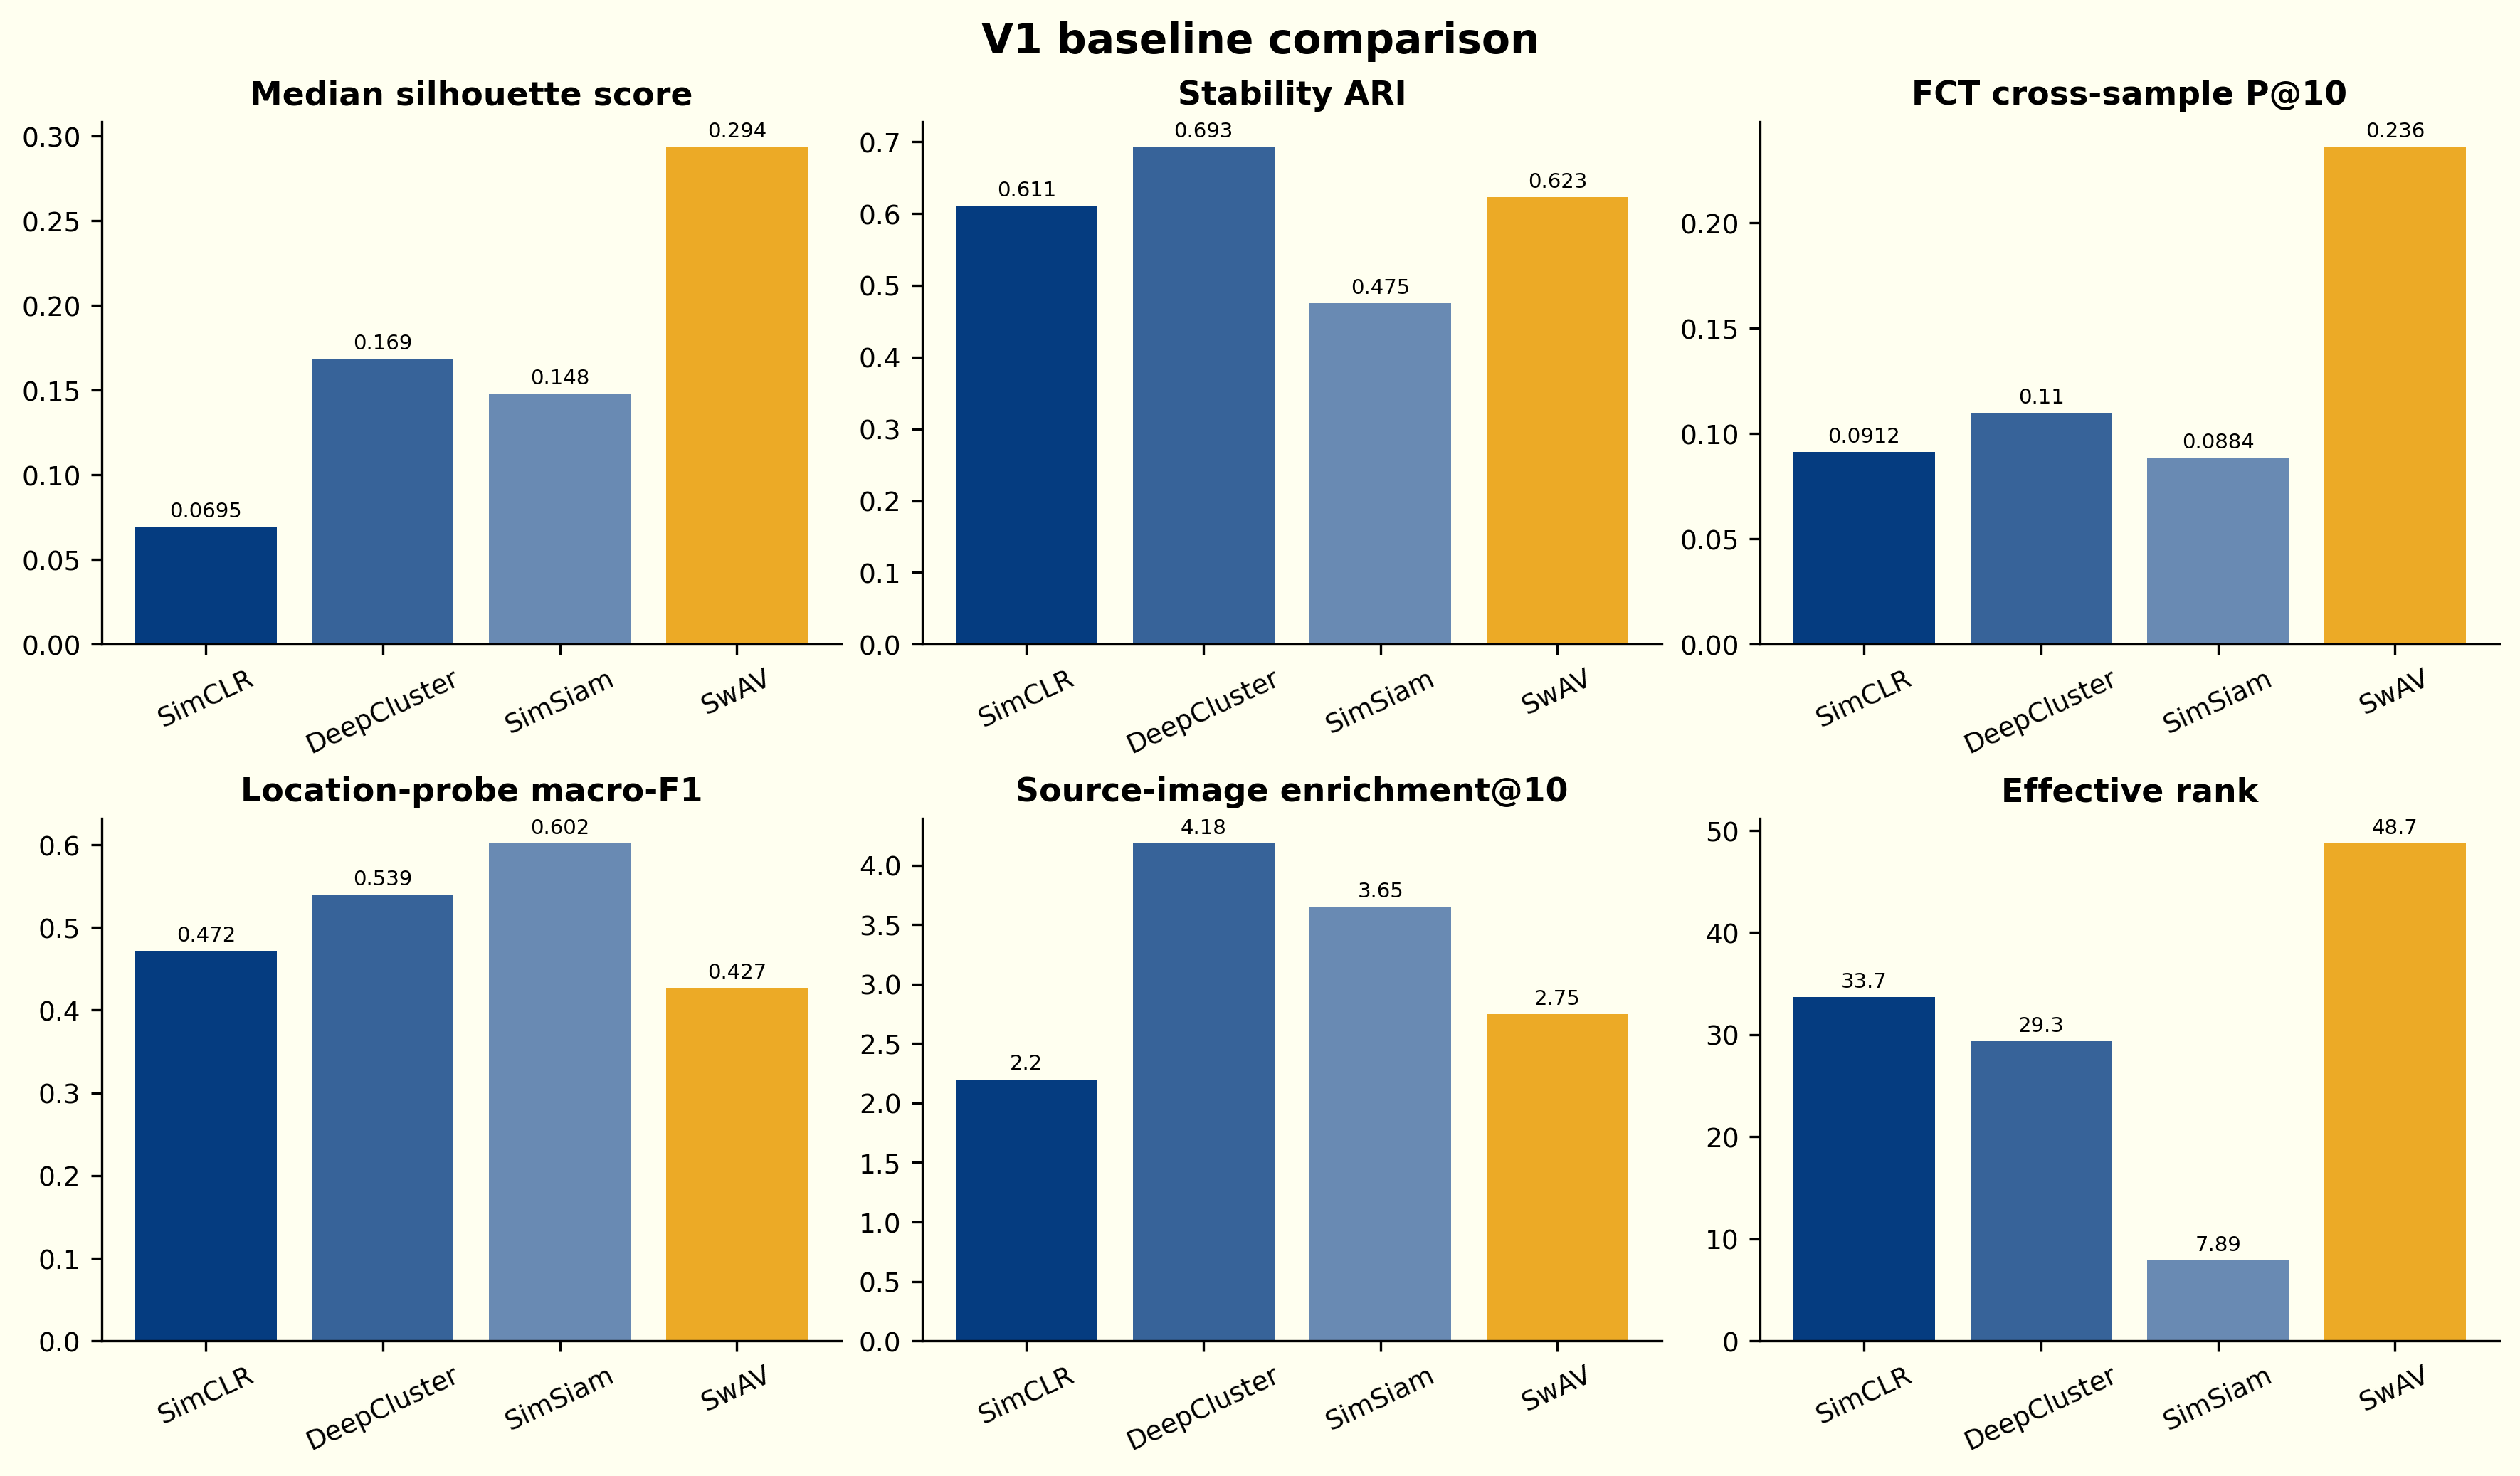

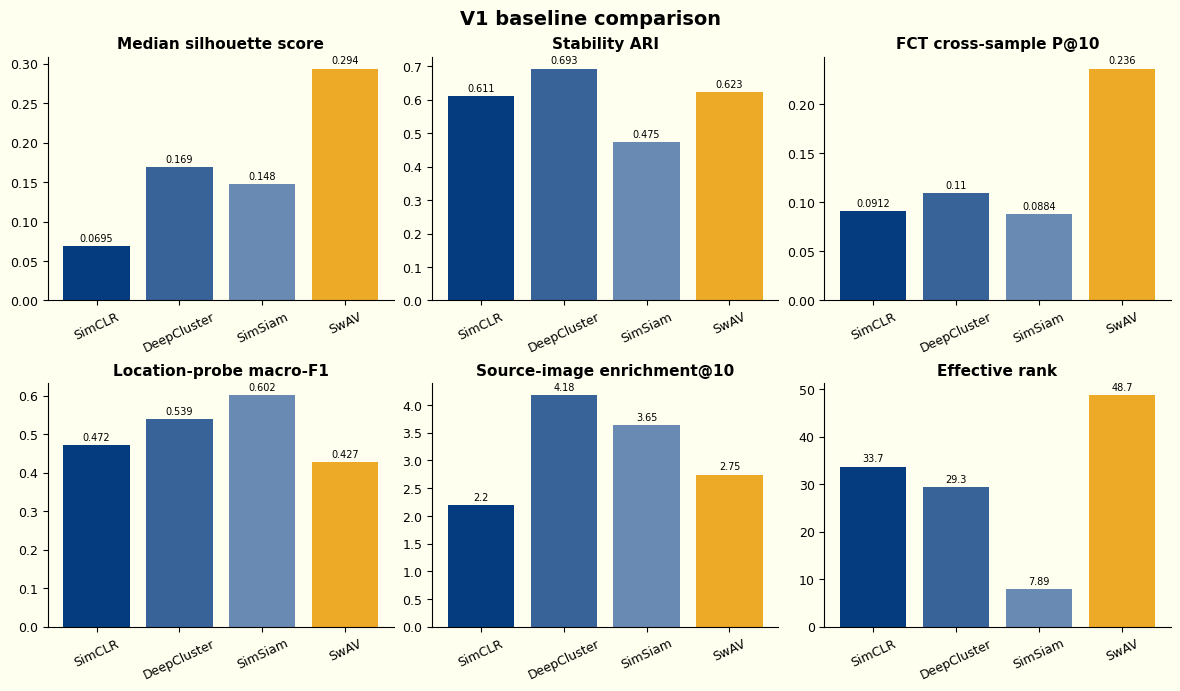

In [2]:
figure = plot_metric_comparison(metrics)
out_path = OUTPUT / "model_comparison_v1_metrics.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)

**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/model_comparison_v1_clustering.png`

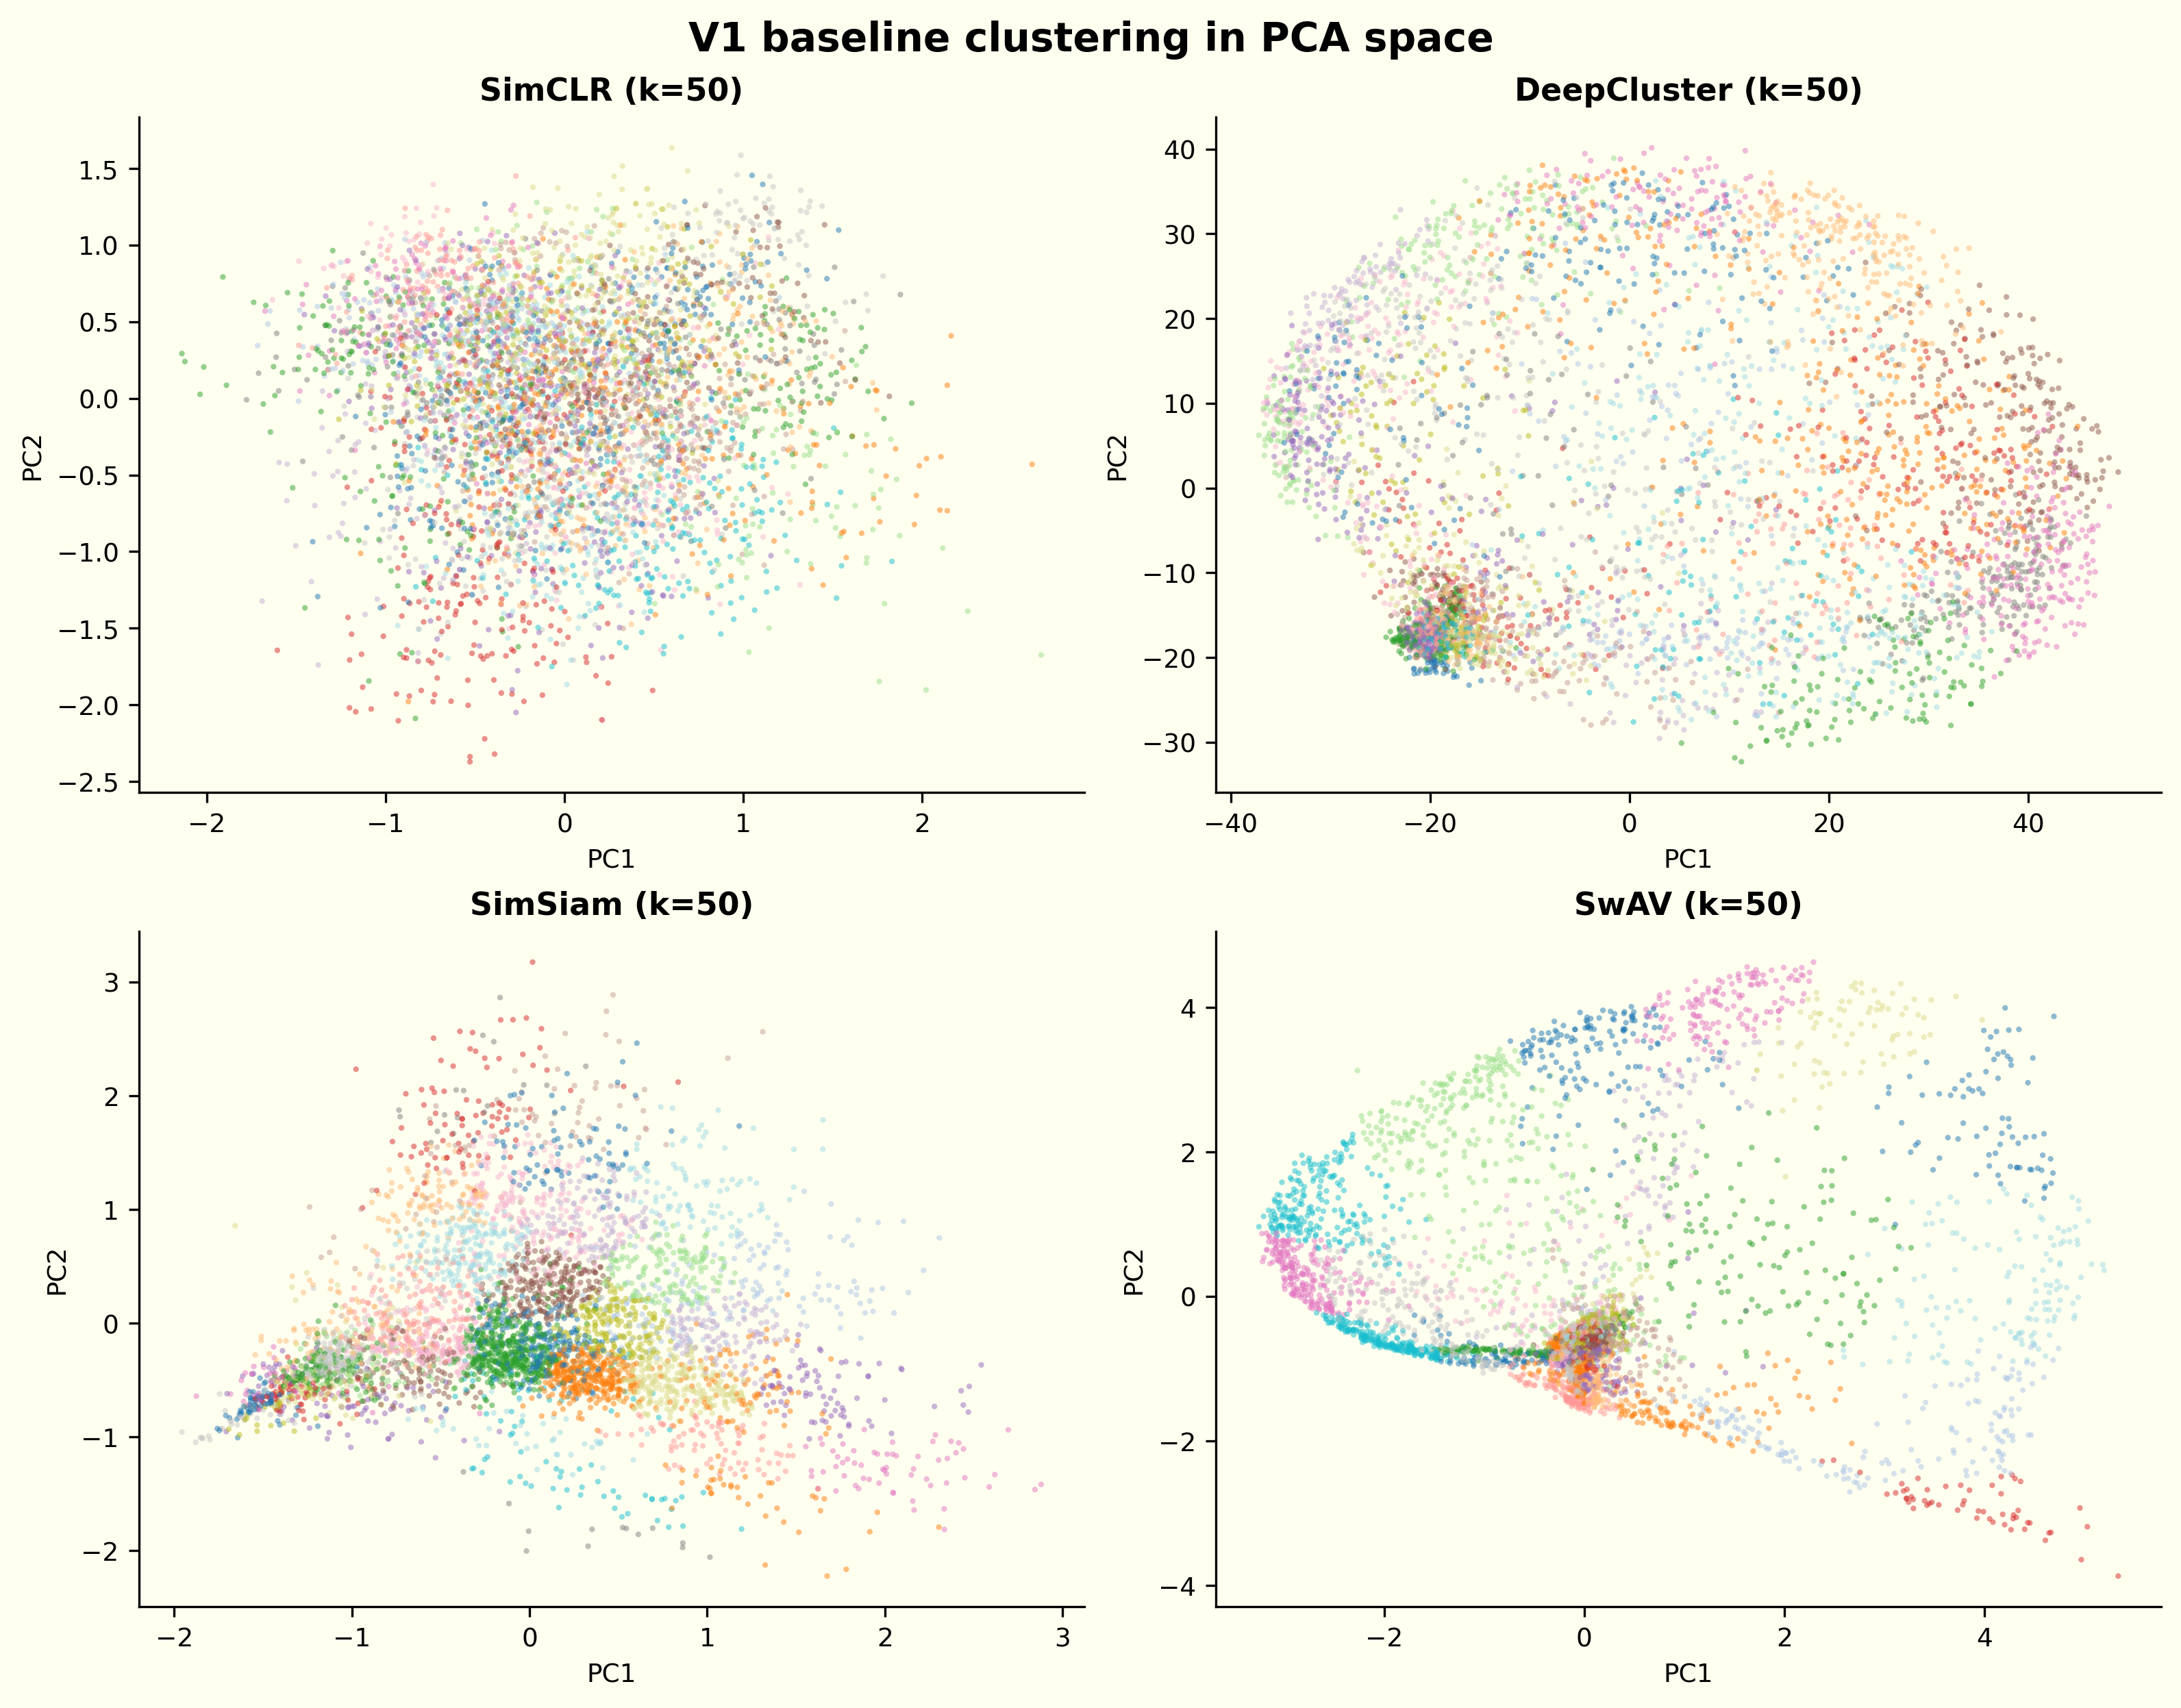

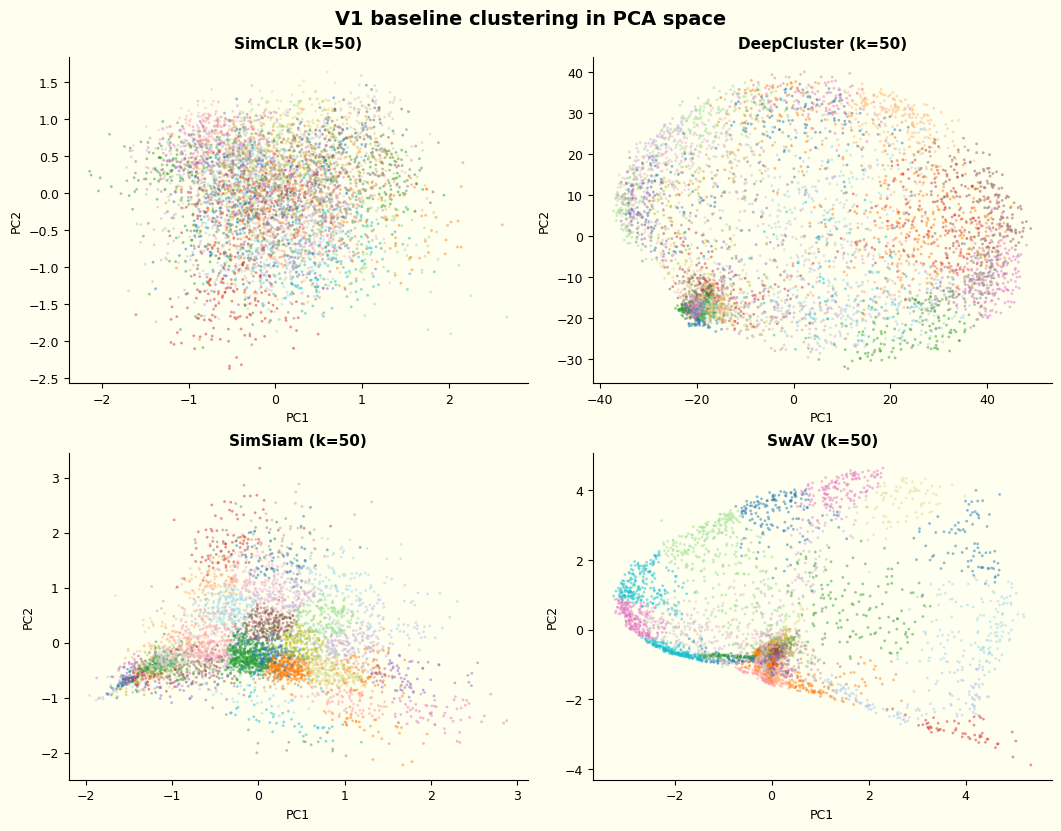

In [3]:
RUN_NAMES = {
    "SimCLR": "hpc/simclr/simclr_resnet18_pooled_broad_natural_seed42_full_3408095",
    "DeepCluster": "hpc/deepcluster/deepcluster_resnet18_pooled_broad_natural_seed42_full_3425705",
    "SimSiam": "hpc/simsiam/simsiam_resnet18_pooled_broad_natural_seed42_full_3438756",
    "SwAV": "hpc/swav/swav_resnet18_pooled_broad_natural_seed42_full_3447013",
}
bundles = {
    name: load_embedding_bundle(RUNS_ROOT / relative / "embeddings/validation_backbone_embeddings.npz")
    for name, relative in RUN_NAMES.items()
}
embeddings = {name: bundle.features for name, bundle in bundles.items()}

figure = plot_cluster_comparison(embeddings, clusters=50)
out_path = OUTPUT / "model_comparison_v1_clustering.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)

**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/model_comparison_v1_crystal_examples.png`

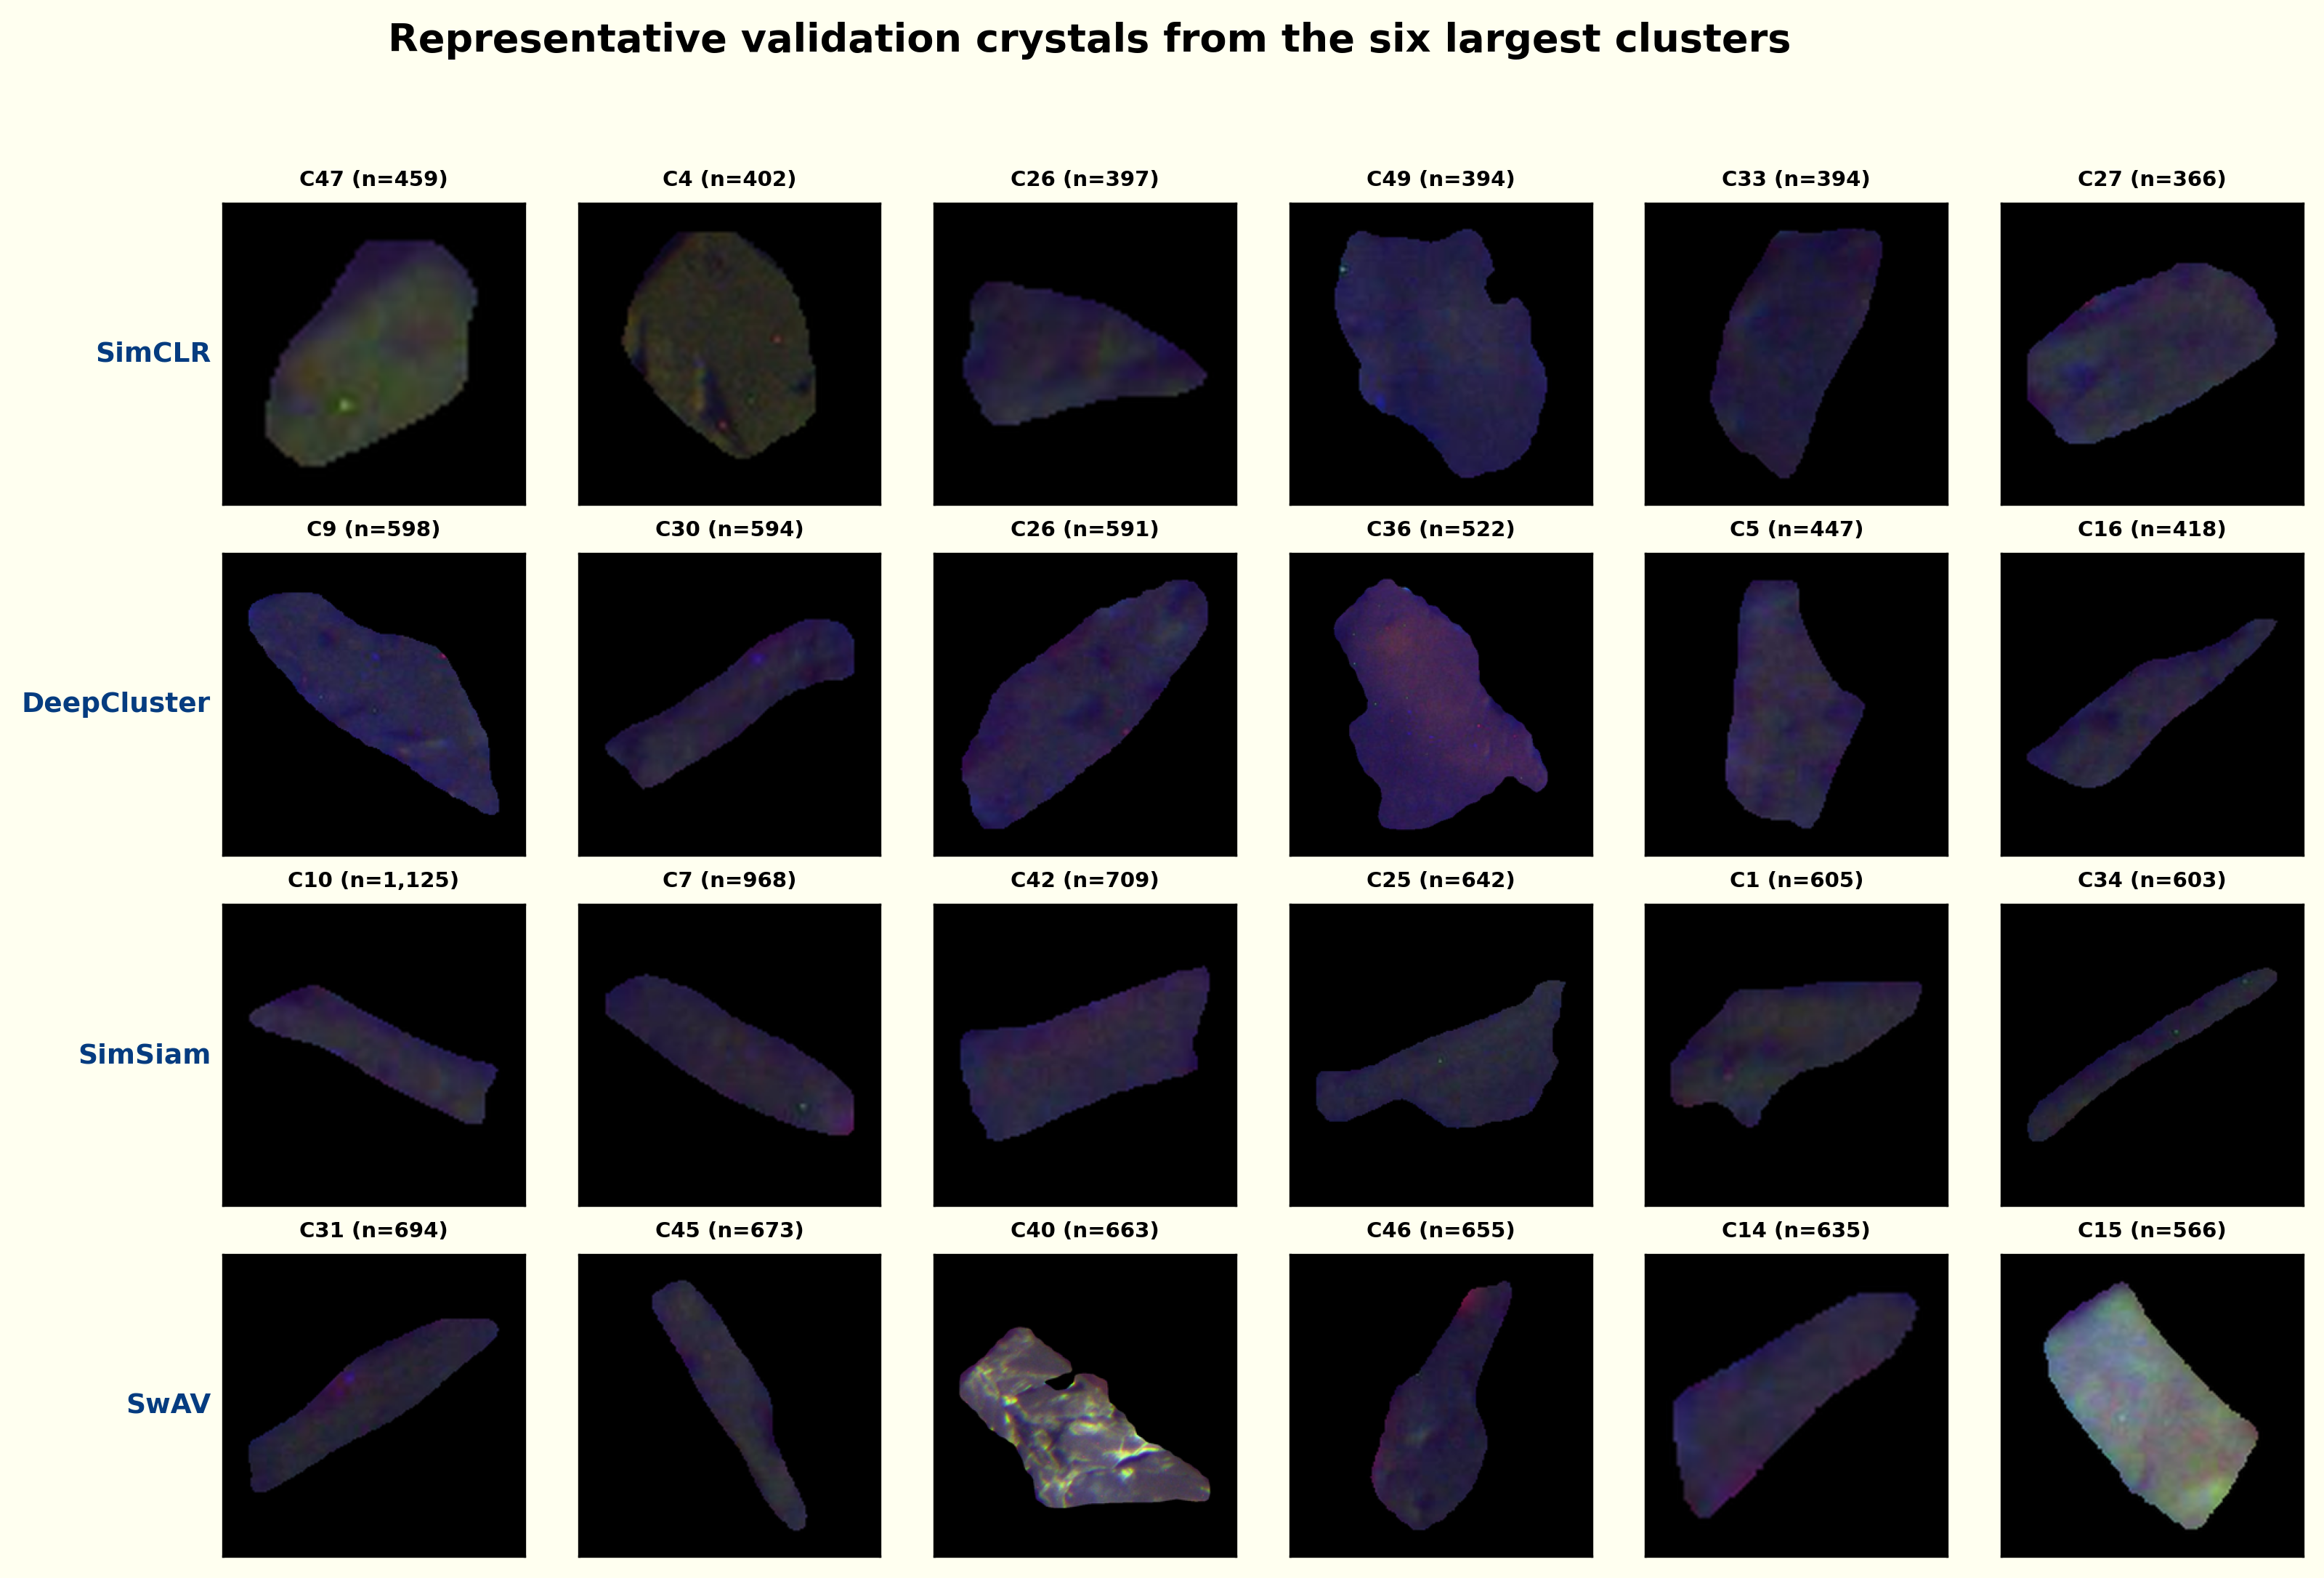

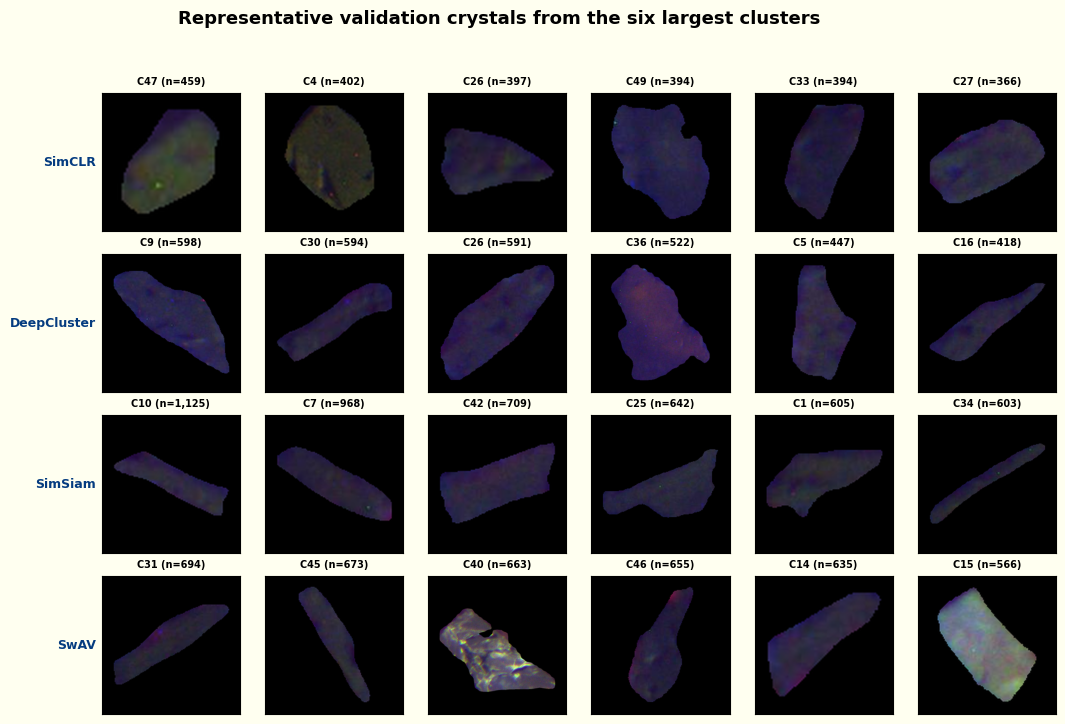

In [4]:
V1_ROOT = DATA_ROOT / "processed/plagnetplus/ssl_unified_v1"
manifest = pd.read_csv(V1_ROOT / "benchmarks/pooled_broad_p80_10_10_v1/manifests/crystals_validation.csv", low_memory=False)
roots = load_image_root_map(V1_ROOT / "metadata/image_root_map.json", data_root=DATA_ROOT)
manifest = manifest.set_index("crystal_id", drop=False)
image_paths = {}
for name, bundle in bundles.items():
    aligned = manifest.loc[bundle.crystal_ids]
    image_paths[name] = [str(roots[str(row.image_root_key)] / str(row.image_relative_path)) for row in aligned.itertuples(index=False)]

figure = plot_model_examples(embeddings, image_paths, clusters=50)
out_path = OUTPUT / "model_comparison_v1_crystal_examples.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)